# Linearized ptychography: Jacobian-ready wide-FOV hBN measurement

This notebook creates the first concrete data product for the linearized-ptychography work. It uses the existing wide-FOV hBN blue-center phase cache:

`../bcenters_base_excited_phases_wide_fov.pkl`

The saved output contains the ingredients needed to apply the local intensity Jacobian without first forming a dense matrix:

- complex base and excited transmission objects
- abTEM scan positions and detector intensities
- the real-space probe at every scan position
- the base detector-plane complex wavefunction

The linearization convention used below is

\[
O_1 = O_0 e^{i h},\qquad
A_R h = -2\operatorname{Im}\left[\Psi_{0,R}^*\,\mathcal F\{\psi_{0,R} h\}\right],
\]

where \(\psi_{0,R}\) is the exit wave in the object plane and \(\Psi_{0,R}\) is the projected wavefunction on the camera.

In [1]:
from pathlib import Path
import json
import pickle
import time

import abtem
import numpy as np
import matplotlib.pyplot as plt

from abtem.waves import Probe
from abtem.core.energy import energy2sigma
from abtem.potentials.iam import PotentialArray
from abtem import PixelatedDetector
from abtem.scan import GridScan

NOTEBOOK_DIR = Path.cwd()
SCRIPTS_DIR = NOTEBOOK_DIR.parent
PHASE_PICKLE = SCRIPTS_DIR / "bcenters_base_excited_phases_wide_fov.pkl"
DATA_DIR = NOTEBOOK_DIR / "data"
DATA_DIR.mkdir(parents=True, exist_ok=True)

print("Notebook dir:", NOTEBOOK_DIR)
print("Phase cache:", PHASE_PICKLE)
print("Output dir:", DATA_DIR)
print("abTEM:", abtem.__version__)

/home/rotem/ptycho_light/.ptycho_light_venv/lib/python3.14/site-packages/torch/cuda/__init__.py:1174: UserWarning: Can't initialize NVML
  raw_cnt = _raw_device_count_nvml()


Notebook dir: /home/rotem/ptycho_light/quantem/scripts/linearized-ptycho
Phase cache: /home/rotem/ptycho_light/quantem/scripts/bcenters_base_excited_phases_wide_fov.pkl
Output dir: /home/rotem/ptycho_light/quantem/scripts/linearized-ptycho/data
abTEM: 1.0.10


## Parameters

The microscope settings follow the existing linearized-model notebooks. The default scan step here is coarser than the reconstruction notebooks so that the saved per-position probe stack remains practical while the Jacobian plumbing is being developed. Lower `SCAN_STEP_SIZE` later if a denser ptychographic scan is needed.

In [2]:
ACC_VOLTAGE = 60e3      # eV
PROBE_SEMIANGLE = 30     # mrad
PROBE_DEFOCUS = 0        # Angstrom
SLICE_THICKNESS = 1.0    # Angstrom bookkeeping slice for a projected phase object

SCAN_STEP_SIZE = 1.5     # Angstrom; set to 0.2 to match notebooks 05/07 exactly
SCAN_ENDPOINT = True
CHUNK_SIZE = 64

OUTPUT_NPZ = DATA_DIR / "hbn_wide_fov_abtem_jacobian_ready_measurement.npz"

print("acc_voltage:", ACC_VOLTAGE)
print("probe_semiangle:", PROBE_SEMIANGLE)
print("probe_defocus:", PROBE_DEFOCUS)
print("slice_thickness:", SLICE_THICKNESS)
print("scan_step_size:", SCAN_STEP_SIZE)
print("scan_endpoint:", SCAN_ENDPOINT)
print("chunk_size:", CHUNK_SIZE)

acc_voltage: 60000.0
probe_semiangle: 30
probe_defocus: 0
slice_thickness: 1.0
scan_step_size: 1.5
scan_endpoint: True
chunk_size: 64


## Load the wide-FOV hBN blue-center phases

In [3]:
with open(PHASE_PICKLE, "rb") as f:
    phase_data = pickle.load(f)

phase_base = np.asarray(phase_data["base"], dtype=np.float32)
phase_excited = np.asarray(phase_data["excited"], dtype=np.float32)
x_ang = np.asarray(phase_data["x"], dtype=np.float32)
y_ang = np.asarray(phase_data["y"], dtype=np.float32)

dx = float(x_ang[1] - x_ang[0])
dy = float(y_ang[1] - y_ang[0])
delta_phase = (phase_excited - phase_base).astype(np.float32)
window_y = np.hamming(delta_phase.shape[0])
window_x = np.hamming(delta_phase.shape[1])
hamming_filter = np.outer(window_y, window_x)
delta_phase *= hamming_filter
phase_excited = phase_base + delta_phase


object_base = np.exp(1j * phase_base).astype(np.complex64)
object_excited = np.exp(1j * phase_excited).astype(np.complex64)

print("phase shape:", phase_base.shape)
print("x range:", float(x_ang[0]), float(x_ang[-1]), "dx:", dx)
print("y range:", float(y_ang[0]), float(y_ang[-1]), "dy:", dy)
print("base phase range:", float(phase_base.min()), float(phase_base.max()))
print("excited phase range:", float(phase_excited.min()), float(phase_excited.max()))
print("delta phase range:", float(delta_phase.min()), float(delta_phase.max()))
print("max |delta phase|:", float(np.max(np.abs(delta_phase))))

phase shape: (251, 251)
x range: -12.0 12.0 dx: 0.09599971771240234
y range: -12.0 12.0 dy: 0.09599971771240234
base phase range: -0.03724941611289978 0.19700032472610474
excited phase range: -0.03996143862605095 0.19678565859794617
delta phase range: -0.02105947770178318 0.012852153740823269
max |delta phase|: 0.02105947770178318


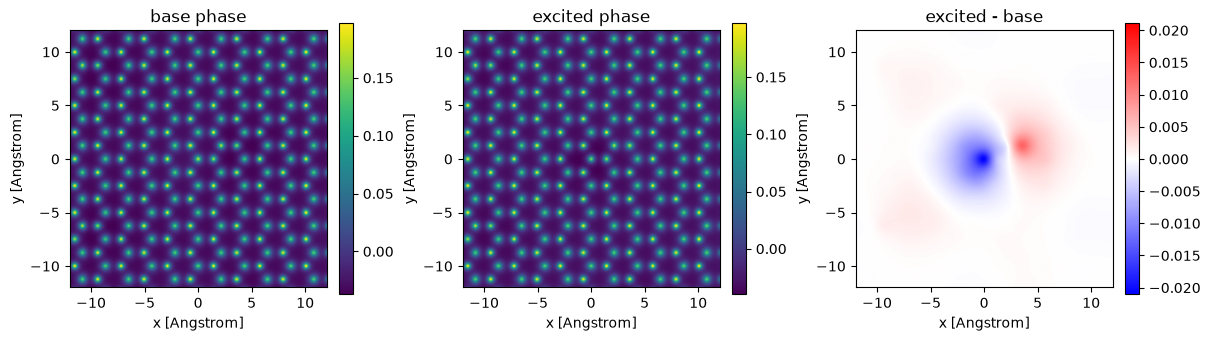

In [4]:
extent = [float(x_ang[0]), float(x_ang[-1]), float(y_ang[0]), float(y_ang[-1])]
vmax = float(np.max(np.abs(delta_phase)))
fig, axes = plt.subplots(1, 3, figsize=(12, 3.6), constrained_layout=True)
for ax, image, title, cmap, lim in [
    (axes[0], phase_base, "base phase", "viridis", None),
    (axes[1], phase_excited, "excited phase", "viridis", None),
    (axes[2], delta_phase, "excited - base", "bwr", vmax),
]:
    im = ax.imshow(
        image,
        extent=extent,
        origin="lower",
        cmap=cmap,
        vmin=(-lim if lim is not None else None),
        vmax=(lim if lim is not None else None),
    )
    ax.set_xlabel("x [Angstrom]")
    ax.set_ylabel("y [Angstrom]")
    ax.set_title(title)
    fig.colorbar(im, ax=ax, shrink=0.8)
plt.show()

## Build abTEM potentials, probe, scan, and detector

In [5]:
sigma = float(energy2sigma(ACC_VOLTAGE))


def make_potential(phase_image):
    projected_potential = phase_image / (sigma * SLICE_THICKNESS)
    return PotentialArray(
        array=projected_potential[np.newaxis].astype(np.float32),
        slice_thickness=SLICE_THICKNESS,
        sampling=(dx, dy),
    )


potential_base = make_potential(phase_base)
potential_excited = make_potential(phase_excited)

probe = Probe(
    energy=ACC_VOLTAGE,
    semiangle_cutoff=PROBE_SEMIANGLE,
    defocus=PROBE_DEFOCUS,
)
probe.match_grid(potential_base)

scan = GridScan(
    start=(0.0, 0.0),
    end=potential_base.extent,
    potential=potential_base,
    sampling=SCAN_STEP_SIZE,
    endpoint=SCAN_ENDPOINT,
)
scan_positions_xy = scan.get_positions().astype(np.float32)
scan_positions_flat_xy = scan_positions_xy.reshape(-1, 2)

detector = PixelatedDetector(max_angle="valid")

print("potential extent [Angstrom]:", potential_base.extent)
print("scan positions:", scan_positions_xy.shape, "total:", len(scan_positions_flat_xy))
print("first/last scan position:", scan_positions_flat_xy[0], scan_positions_flat_xy[-1])

potential extent [Angstrom]: (24.09592914581299, 24.09592914581299)
scan positions: (18, 18, 2) total: 324
first/last scan position: [0. 0.] [24.095928 24.095928]


## Generate the abTEM 4D-STEM intensities

In [6]:
t0 = time.time()
base_meas = probe.scan(potential_base, scan=scan, detectors=detector)
base_meas.compute()
intensity_base = np.asarray(base_meas.array).astype(np.float32)
print("base measurement:", intensity_base.shape, intensity_base.dtype, f"{time.time() - t0:.1f} s")

t0 = time.time()
excited_meas = probe.scan(potential_excited, scan=scan, detectors=detector)
excited_meas.compute()
intensity_excited = np.asarray(excited_meas.array).astype(np.float32)
print("excited measurement:", intensity_excited.shape, intensity_excited.dtype, f"{time.time() - t0:.1f} s")

detector_shape = intensity_base.shape[-2:]
detector_sampling_inv_ang = tuple(float(v) for v in base_meas.sampling)
print("detector shape:", detector_shape)
print("detector sampling [1/Angstrom]:", detector_sampling_inv_ang)

tasks:  33%|###3      | 2/6 [00:00<00:01,  3.21it/s]

base measurement: (18, 18, 119, 119) float32 1.2 s


tasks:  83%|########3 | 5/6 [00:00<00:00,  6.42it/s]

excited measurement: (18, 18, 119, 119) float32 0.8 s
detector shape: (119, 119)
detector sampling [1/Angstrom]: (0.041500786043511595, 0.041500786043511595)


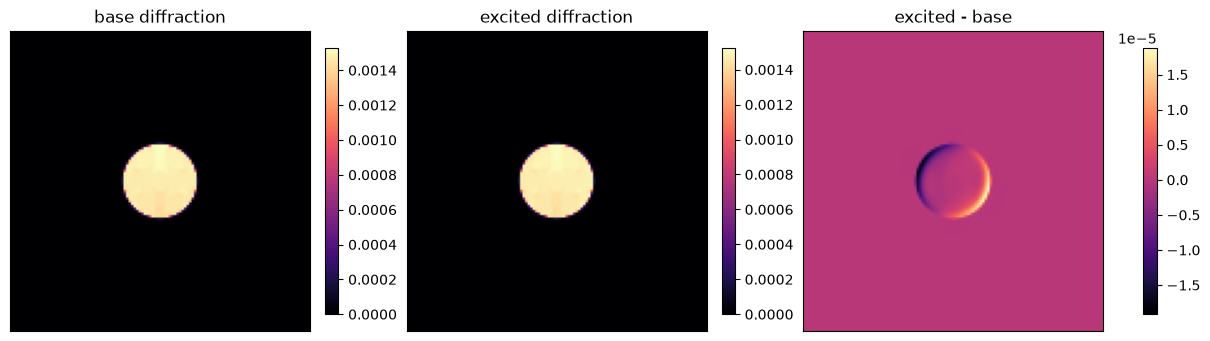

In [7]:
center_scan = tuple(s // 2 for s in intensity_base.shape[:2])
fig, axes = plt.subplots(1, 3, figsize=(12, 3.5), constrained_layout=True)
for ax, image, title in [
    (axes[0], intensity_base[center_scan], "base diffraction"),
    (axes[1], intensity_excited[center_scan], "excited diffraction"),
    (axes[2], intensity_excited[center_scan] - intensity_base[center_scan], "excited - base"),
]:
    im = ax.imshow(image, cmap="magma")
    ax.set_title(title)
    ax.set_xticks([])
    ax.set_yticks([])
    fig.colorbar(im, ax=ax, shrink=0.8)
plt.show()

## Build probe and camera-wave stacks for the Jacobian

For a single projected phase slice, abTEM's multislice intensity is reproduced by
\(\left|\mathcal F\{P_R O_0\}\right|^2\) after cropping to the detector pixels. We save `probe_realspace_by_scan` and `camera_wave_base`; together with `object_base`, these are the reusable ingredients for Jacobian-vector products.

In [8]:
def fft2_camera(exit_wave):
    return np.fft.fftshift(
        np.fft.fft2(exit_wave, axes=(-2, -1)),
        axes=(-2, -1),
    ).astype(np.complex64)


def crop_center(array, target_shape):
    full_y, full_x = array.shape[-2:]
    target_y, target_x = target_shape
    start_y = (full_y - target_y) // 2
    start_x = (full_x - target_x) // 2
    return array[..., start_y:start_y + target_y, start_x:start_x + target_x]


def jacobian_at_position(probe_realspace, phase_perturbation, object_complex=None):
    """Apply the local intensity Jacobian at a single scan position.

    Given the real-space probe P_R at one position and a real phase perturbation
    h (so that O_1 = O_0 e^{i h}), returns

        Psi_0,R = crop(F{P_R O_0})
        A_R h   = -2 Im[conj(Psi_0,R) crop(F{P_R O_0 h})]

    i.e. the base detector-plane wavefunction and the linearized change in
    detector intensity at that position.
    """
    if object_complex is None:
        object_complex = object_base

    exit_wave_base = probe_realspace * object_complex
    camera_wave_base_position = crop_center(fft2_camera(exit_wave_base), detector_shape)
    perturbed_camera = crop_center(
        fft2_camera(exit_wave_base * phase_perturbation),
        detector_shape,
    )
    linear_delta = -2.0 * np.imag(np.conj(camera_wave_base_position) * perturbed_camera)
    return camera_wave_base_position, linear_delta.astype(np.float32)



In [9]:
def plot_complex(complex_arr, title=None):
    """Plot a complex array as amplitude and phase."""
    fig, axes = plt.subplots(1, 2, figsize=(10, 4), constrained_layout=True)

    for ax, image, title, cmap in [
        (axes[0], np.abs(complex_arr), "Amplitude", "magma"),
        (axes[1], np.angle(complex_arr), "Phase", "twilight"),
    ]:
        im = ax.imshow(image, cmap=cmap)
        ax.set_title(title)
        ax.axis("off")
        fig.colorbar(im, ax=ax, shrink=0.8)

    plt.suptitle(title if title is not None else "Complex array")
    plt.show()

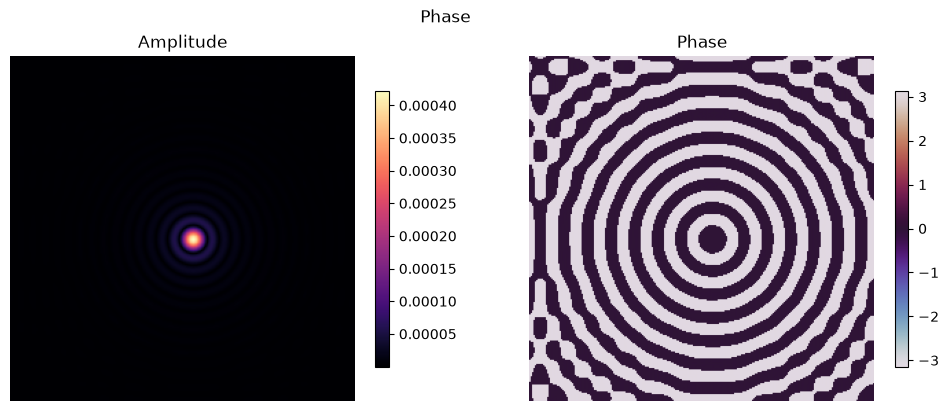

In [10]:
wave = probe.build(scan=list(scan_positions_xy[center_scan]))
probe_realspace = wave.compute()

plot_complex(probe_realspace.array, title="Probe real-space wavefunction")

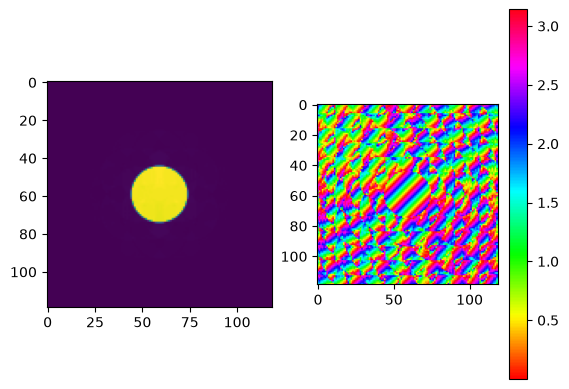

In [11]:
from numpy.fft import fft2, fftshift, ifft2, ifftshift
exit_wf_base = probe_realspace * object_base

# Psi_0,R = crop(F{psi_0,R}) -- the BASE camera wave, with no perturbation applied.
# (This is what conj(Psi_0,R) scales the rows of A_R by; multiplying delta_phase in
# here would make the matrix built below something other than the Jacobian.)
base_wf_on_detector = crop_center(
    fftshift(fft2(ifftshift(exit_wf_base.array))),
    detector_shape,
)
plt.subplot(1,2,1)
plt.imshow(np.abs(base_wf_on_detector))
plt.subplot(1,2,2)
phase_on_cam = np.angle(base_wf_on_detector)
phase_on_cam[phase_on_cam<0] += np.pi
plt.imshow(phase_on_cam, cmap='hsv')
plt.colorbar()

In [12]:
import torch

ny, nx = exit_wf_base.shape
n_object = ny * nx
det_y, det_x = detector_shape

def centered_dft_matrix_cropped(n_full, n_crop, device='cuda'):
    """The rows of fftshift(fft(ifftshift(.))) that crop_center keeps, as a matrix.

    For odd n_full, fftshift o fft o ifftshift is the centered DFT

        F[k, p] = exp(-2j pi (k - c) (p - c) / n_full),   c = n_full // 2,

    and crop_center keeps rows [start, start + n_crop) with start = (n_full - n_crop) // 2.
    Building it from the definition costs n_crop * n_full entries instead of
    FFT-ing an n_full**2-sized identity basis.
    """
    centre = n_full // 2
    start = (n_full - n_crop) // 2
    k = torch.arange(start, start + n_crop, device=device, dtype=torch.float64) - centre
    p = torch.arange(n_full, device=device, dtype=torch.float64) - centre
    return torch.exp(
        1j * (-2.0 * torch.pi * torch.outer(k, p) / n_full)
    ).to(torch.complex64)

ft_rows_y = centered_dft_matrix_cropped(ny, det_y)   # (det_y, ny)
ft_rows_x = centered_dft_matrix_cropped(nx, det_x)   # (det_x, nx)


In [13]:
exit_wf_base_cs = torch.tensor(
    exit_wf_base.array, 
    device='cuda'
).reshape(-1) 

base_wf_on_detector_cs = torch.tensor(
    base_wf_on_detector, 
    device='cuda'
).reshape(-1) 

ft_operator = torch.kron(ft_rows_y, ft_rows_x)

A_R = -2 * torch.imag(
    torch.conj(base_wf_on_detector_cs)[:, None] * 
    ft_operator 
    * exit_wf_base_cs[None, :]
)
torch.cuda.empty_cache()

ft_operator.shape, base_wf_on_detector_cs.shape, exit_wf_base_cs.shape, A_R.shape

(torch.Size([14161, 63001]),
 torch.Size([14161]),
 torch.Size([63001]),
 torch.Size([14161, 63001]))

# Sanity checks
Numerical validataion that everything checks out. 

(np.float64(-0.5), np.float64(118.5), np.float64(118.5), np.float64(-0.5))

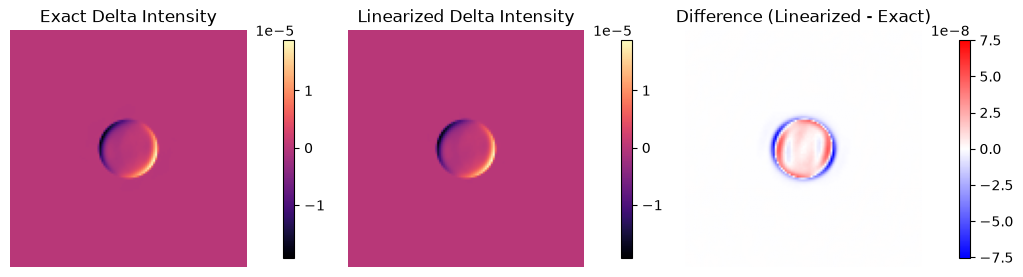

In [14]:
delta_phase_cs = torch.tensor(
    delta_phase.reshape(-1), 
    device='cuda'
)
linearized_delta_intensity_cs = A_R @ delta_phase_cs
linearized_delta_intensity = linearized_delta_intensity_cs.cpu().numpy().reshape(detector_shape)

plt.figure(figsize=(10, 8), constrained_layout=True)
plt.subplot(1,3,1)
exact_delta_intensity = intensity_excited[center_scan] - intensity_base[center_scan]
im = plt.imshow(exact_delta_intensity, cmap='magma')
plt.colorbar(im, fraction=0.046, pad=0.04)
plt.title('Exact Delta Intensity')
plt.axis('off')

plt.subplot(1,3,2)
im = plt.imshow(linearized_delta_intensity, cmap='magma')
plt.colorbar(im, fraction=0.046, pad=0.04)
plt.title('Linearized Delta Intensity')
plt.axis('off')

plt.subplot(1,3,3)
linearization_error = linearized_delta_intensity - exact_delta_intensity
c_extent = np.max(np.abs(linearization_error))
im = plt.imshow(linearization_error, cmap='bwr', vmin=-c_extent, vmax=c_extent)
plt.colorbar(im, fraction=0.046, pad=0.04)
plt.title('Difference (Linearized - Exact)')
plt.axis('off')

# study detectability from the acquired Jacobian 

In [15]:
# Runnig SVD to extract identifiable and null nodes in the differentail phase
U, S, V = torch.svd(A_R)

[W1011 14:47:28.715922306 CUDACachingAllocator.cpp:3934] memory allocation failed with OOM on device 0 while trying to allocate 8034189312 bytes (free: 5550768128, total: 33668268032).
[W1011 14:47:28.716018287 CUDACachingAllocator.cpp:3934] memory allocation failed with OOM on device 0 while trying to allocate 8034189312 bytes (free: 5550768128, total: 33668268032).
/tmp/ipykernel_1665257/2136767472.py:2: UserWarning: nvmlInit_v2 failed; omitting per-process memory info from CUDA out-of-memory messages. (Triggered internally at /__w/pytorch/pytorch/c10/cuda/CUDACachingAllocator.cpp:1348.)
  U, S, V = torch.svd(A_R)


OutOfMemoryError: CUDA out of memory. Tried to allocate 7.48 GiB. GPU 0 has a total capacity of 31.36 GiB of which 5.17 GiB is free. Of the allocated memory 17.40 GiB is allocated by PyTorch, and 2.55 GiB is reserved by PyTorch but unallocated. If reserved but unallocated memory is large try setting PYTORCH_CUDA_ALLOC_CONF=expandable_segments:True to avoid fragmentation.  See documentation for Memory Management  (https://docs.pytorch.org/docs/stable/notes/cuda.html#optimizing-memory-usage-with-pytorch-cuda-alloc-conf)

Text(0, 0.5, 'Singular value')

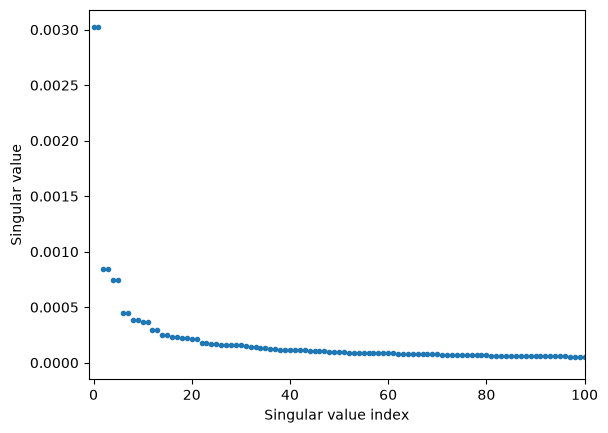

In [ ]:
plt.plot(S.cpu().numpy(), '.')
plt.xlim(-1, 100)
plt.xlabel('Singular value index')
plt.ylabel('Singular value')

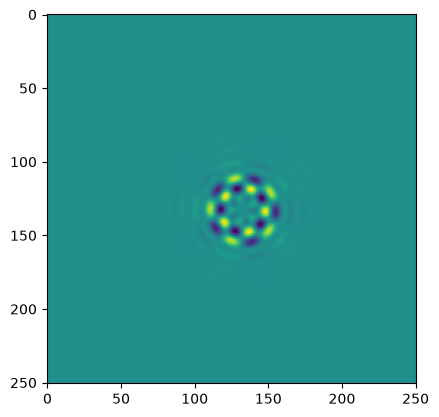

In [ ]:
plt.imshow(V[:,6].reshape(251, 251).cpu().numpy())

Text(0, 0.5, 'DP effect')

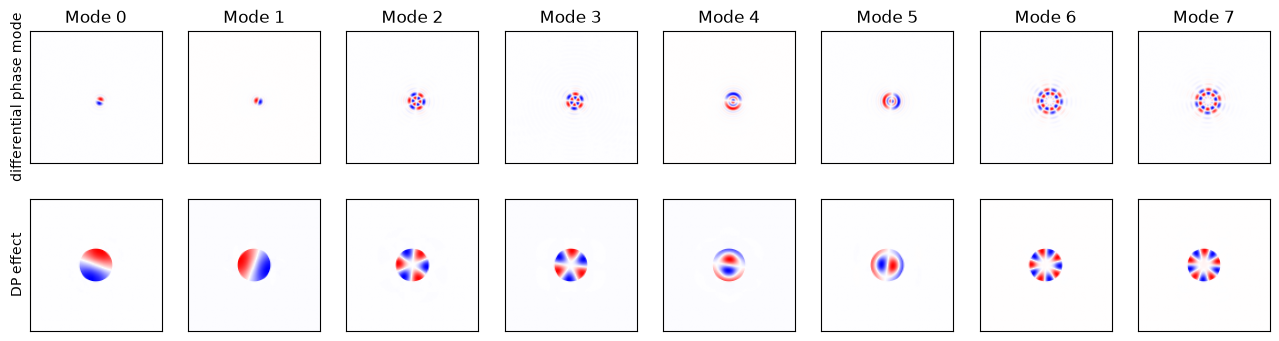

In [ ]:
n_to_plot = 8
plt.figure(figsize=(16, 4))
for i in range(n_to_plot):
    plt.subplot(2, n_to_plot, i+1)
    plt.imshow(V[:,i].reshape(251, 251).cpu().numpy(), cmap='bwr')
    plt.title(f'Mode {i}')
    plt.xticks([])
    plt.yticks([])

    plt.subplot(2, n_to_plot, i+1 + n_to_plot)
    plt.imshow(U[:,i].reshape(119, 119).cpu().numpy(), cmap='bwr')
    plt.xticks([])
    plt.yticks([])

plt.subplot(2, n_to_plot, 1)
plt.ylabel('differential phase mode')
plt.subplot(2, n_to_plot, n_to_plot + 1)
plt.ylabel('DP effect')

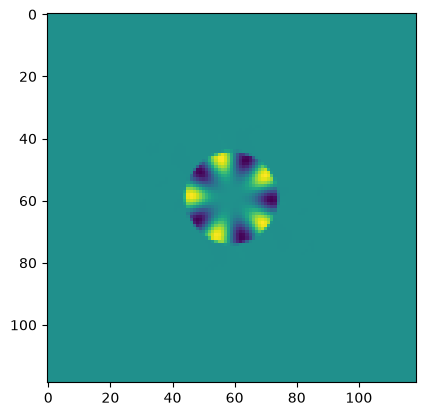

In [ ]:
plt.imshow(U[:,6].reshape(119, 119).cpu().numpy())